# Gate 2: looking at the dreams

Three DDPMs per agent, identical except for their training set: `path_weighted` | `path_uniform` | `random_uniform`.
64 samples each with the same noise seed. **Pass if** `path_weighted` differs visibly or on at least one statistic
from `random_uniform` without memorising. "No difference" is a valid result.

Two references keep the statistics honest:
- **real crops** drawn from each training set exactly as the trainer draws them, which shows whether a sample difference reflects a *data* difference;
- a **noise floor** for each statistic: the same distance between two independent batches of 64 real crops from one set. A model-vs-model distance below the floor is not a difference.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn.functional as F
from matplotlib.colors import rgb_to_hsv
ROOT = Path.cwd().parent if Path.cwd().name == 'analysis' else Path.cwd()
import sys; sys.path.insert(0, str(ROOT))
from gen.train_ddpm import random_crops
tiles_all = np.load(ROOT/'data/tiles.npy', mmap_mode='r')
idx = pd.read_parquet(ROOT/'data/tiles.parquet')
SETS = ['path_weighted', 'path_uniform', 'random_uniform']
agents = sorted(p.name for p in (ROOT/'runs/ddpm').iterdir() if all((p/s/'samples.npy').exists() for s in SETS))
print('agents with all three models:', agents)
pd.set_option('display.precision', 4, 'display.width', 200)
dev = 'cuda'

agents with all three models: ['baseline_s0', 'myopic_s0']


In [2]:
def set_tiles(agent, s):
    sets = pd.read_parquet(ROOT/f'data/sets/{agent}/sets.parquet')
    return sets[sets.set == s].reset_index(drop=True)

def real_crops(agent, s, n, seed):
    st = set_tiles(agent, s)
    t = torch.from_numpy(np.ascontiguousarray(tiles_all[st.tile_idx.values])).to(dev)
    w = torch.tensor(st.weight.values, dtype=torch.float32, device=dev)
    g = torch.Generator(device=dev).manual_seed(seed)
    x = random_crops(t, torch.multinomial(w, n, replacement=True, generator=g), g)
    return ((x + 1) * 127.5).round().clamp(0, 255).byte().permute(0, 2, 3, 1).cpu().numpy()

samples = {a: {s: np.load(ROOT/f'runs/ddpm/{a}/{s}/samples.npy') for s in SETS} for a in agents}
reals = {a: {s: real_crops(a, s, 64, 1) for s in SETS} for a in agents}
for a in agents:
    print(a, json.loads((ROOT/f'data/sets/{a}/info.json').read_text()))

baseline_s0 {'run': 'baseline_s0', 'alpha_s': 1.0, 'alpha_b': 0.5, 'seed': 0, 'n_tiles': 427, 'n_tv_dropped': 7, 'weight_min': 0.27849944683154876, 'weight_max': 5.0, 'weight_mean': 1.3916936076320487, 'frac_clipped_low': 0.0, 'frac_clipped_high': 0.07259953161592506, 'effective_n': 213.62895791185719, 'overlap_path_random': 99}
myopic_s0 {'run': 'myopic_s0', 'alpha_s': 1.0, 'alpha_b': 0.5, 'seed': 0, 'n_tiles': 362, 'n_tv_dropped': 3, 'weight_min': 0.21232481103354087, 'weight_max': 5.0, 'weight_mean': 1.3178032940120676, 'frac_clipped_low': 0.0, 'frac_clipped_high': 0.0718232044198895, 'effective_n': 183.8246914153739, 'overlap_path_random': 71}


## 1. Side-by-side contact sheets
Top row: samples. Bottom row: real training crops from the same set (weighted like training).

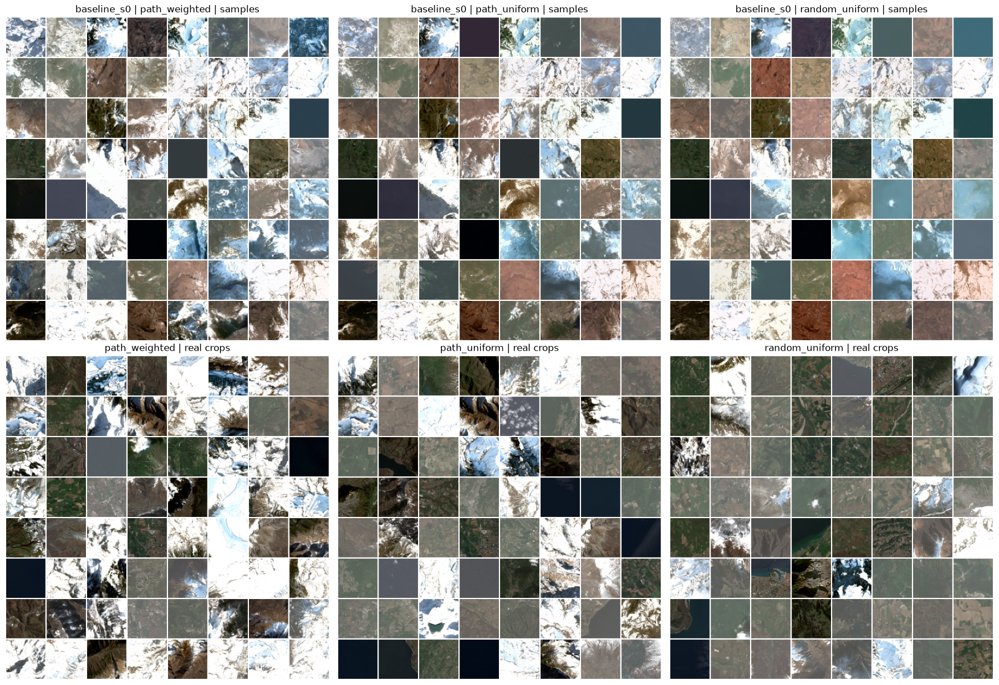

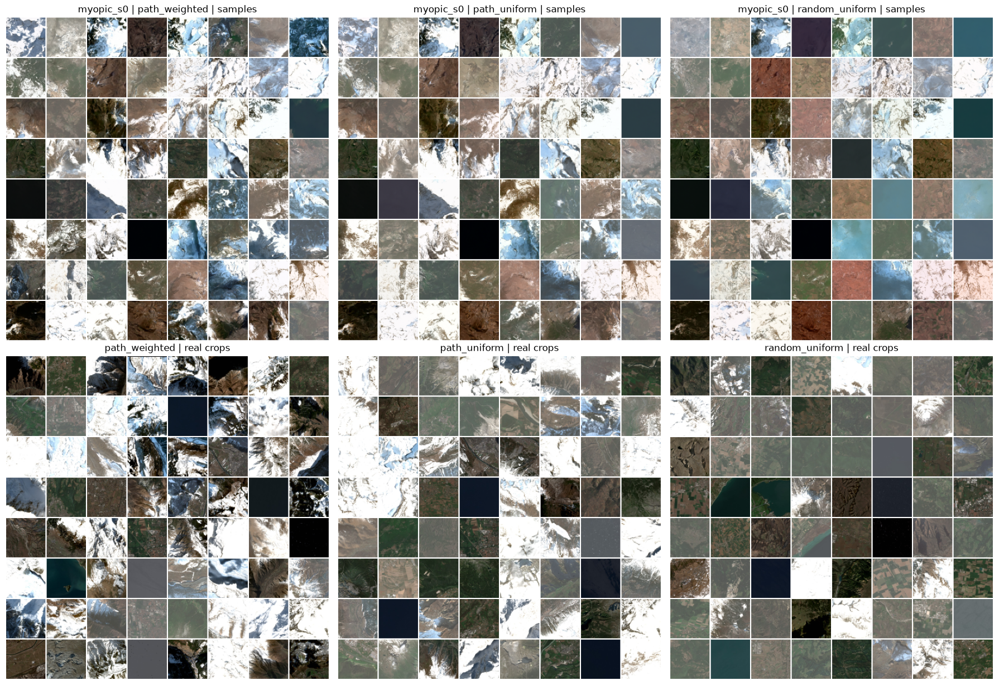

In [3]:
def grid(imgs, n=8):
    g = np.full((n * 66, n * 66, 3), 255, np.uint8)
    for i, im in enumerate(imgs[: n * n]):
        r, c = divmod(i, n); g[r * 66 + 1:r * 66 + 65, c * 66 + 1:c * 66 + 65] = im
    return g
for a in agents:
    fig, axes = plt.subplots(2, 3, figsize=(18, 12.4))
    for j, s in enumerate(SETS):
        axes[0, j].imshow(grid(samples[a][s])); axes[0, j].set_title(f'{a} | {s} | samples'); axes[0, j].axis('off')
        axes[1, j].imshow(grid(reals[a][s])); axes[1, j].set_title(f'{s} | real crops'); axes[1, j].axis('off')
    fig.tight_layout(); fig.savefig(ROOT/f'notes/img/gate2_sheets_{a}.png', dpi=70); plt.show()

## 2. Memorisation check
For each sample: the nearest 64×64 window, by pixel L2, among *all* windows (stride 1) of all training tiles, under all 8 rotations and flips.
This is an exhaustive search done as a convolution. Reference: the same nearest distance for 64 real crops from tiles **not** in that training set.
If samples sit much closer to the training data than unseen real imagery does, the model is copying.

In [4]:
D8 = [(k, f) for f in (False, True) for k in range(4)]
def d8(x):  # x [n,3,64,64] -> [8n,3,64,64]
    return torch.cat([torch.rot90(x.flip(-1) if f else x, k, (-2, -1)) for k, f in D8])

@torch.no_grad()
def nearest(q_u8, tile_ids, chunk=3):
    q = torch.from_numpy(q_u8).to(dev).permute(0, 3, 1, 2).float() / 255
    n = len(q); qq = d8(q)                                   # 8n kernels
    qn = (qq ** 2).sum((1, 2, 3))
    best = torch.full((n,), float('inf'), device=dev); arg = torch.zeros((n, 3), dtype=torch.long, device=dev)
    ones = torch.ones(1, 3, 64, 64, device=dev)
    for c0 in range(0, len(tile_ids), chunk):
        ids = tile_ids[c0:c0 + chunk]
        t = torch.from_numpy(np.ascontiguousarray(tiles_all[ids])).to(dev).permute(0, 3, 1, 2).float() / 255
        with torch.autocast('cuda', dtype=torch.float16):
            xc = F.conv2d(t, qq)                             # [B, 8n, 193, 193]
        tn = F.conv2d(t ** 2, ones)                          # [B, 1, 193, 193]
        d = (tn + qn[None, :, None, None] - 2 * xc.float()).clamp_min(0)
        d = d.view(len(ids), 8, n, -1).amin(1)               # min over D8 -> [B, n, P]
        v, pos = d.permute(1, 0, 2).reshape(n, -1).min(1)
        better = v < best
        best = torch.where(better, v, best)
        b_tile = pos // d.shape[-1]; b_pos = pos % d.shape[-1]
        new = torch.stack([torch.as_tensor(ids, device=dev)[b_tile], b_pos // 193, b_pos % 193], 1)
        arg[better] = new[better]
    arg = arg.cpu().numpy()
    # exact fp32 RMSE of the winning window (the fp16 search leaves ~1 RMSE of numerical noise)
    rmse = np.empty(n)
    for i, (t, y, x) in enumerate(arg):
        w = torch.from_numpy(np.ascontiguousarray(tiles_all[t, y:y + 64, x:x + 64])).to(dev).permute(2, 0, 1).float() / 255
        rmse[i] = float(((d8(q[i:i + 1]) - w[None]) ** 2).mean((1, 2, 3)).min().sqrt()) * 255
    return rmse, arg

mem = {}
pool = np.flatnonzero(~idx.tv.values)
for a in agents:
    for s in SETS:
        tr = np.sort(set_tiles(a, s).tile_idx.unique())
        rng = np.random.default_rng(7)
        outside = rng.choice(np.setdiff1d(pool, tr), 64, replace=False)
        o = tiles_all[outside]; oy, ox = rng.integers(0, 193, 64), rng.integers(0, 193, 64)
        ref = np.stack([o[i, oy[i]:oy[i] + 64, ox[i]:ox[i] + 64] for i in range(64)])
        r_s, a_s = nearest(samples[a][s], tr)
        r_r, _ = nearest(ref, tr)
        mem[(a, s)] = dict(sample_rmse=r_s, ref_rmse=r_r, arg=a_s, textured_s=samples[a][s].reshape(64, -1).std(1) > 12, textured_r=ref.reshape(64, -1).std(1) > 12)
# Flat images (open sea, saturated snow) match any other flat image at RMSE ~0, so nearness says
# nothing about copying for them. "textured" = pixel std > 12 (0-255); the copy test is read on those.
rows = []
for (a, s), m in mem.items():
    ts, tr_ = m['textured_s'], m['textured_r']
    rows.append({'agent': a, 'set': s, 'sample_nn_rmse_median': np.median(m['sample_rmse']), 'unseen_real_nn_rmse_median': np.median(m['ref_rmse']),
                 'textured_samples': int(ts.sum()), 'textured_sample_nn_median': np.median(m['sample_rmse'][ts]) if ts.any() else np.nan,
                 'textured_sample_nn_min': m['sample_rmse'][ts].min() if ts.any() else np.nan,
                 'textured_unseen_nn_median': np.median(m['ref_rmse'][tr_]) if tr_.any() else np.nan,
                 'textured_unseen_nn_min': m['ref_rmse'][tr_].min() if tr_.any() else np.nan,
                 'frac_textured_samples_closer_than_any_unseen': (m['sample_rmse'][ts] < m['ref_rmse'][tr_].min()).mean() if ts.any() and tr_.any() else np.nan})
memtab = pd.DataFrame(rows).set_index(['agent', 'set'])
memtab

sample_nn_rmse_median  unseen_real_nn_rmse_median  textured_samples  textured_sample_nn_median  textured_sample_nn_min  textured_unseen_nn_median  textured_unseen_nn_min  \
agent       set                                                                                                                                                                                         
baseline_s0 path_weighted                 38.4430                     13.2633                59                    39.9851                 11.2937                    17.7070                  9.7296   
            path_uniform                  28.2547                     13.2633                52                    32.8864                 11.6024                    17.7070                  9.7296   
            random_uniform                23.5451                     15.1969                52                    32.0989                  6.1168                    18.6463                 10.6944   
myopic_s0   path_weighted                 37.4612                     14.4214                60                    39.4998                 10.7742                    17.4880                 12.3634   
            path_uniform                  29.6325                     14.4214                56                    33.3294                  7.2657                    17.4880                 12.3634   
            random_uniform                21.5304                     15.1364                52                    25.8927                  2.7454                    20.4531                  9.5064   

                            frac_textured_samples_closer_than_any_unseen  
agent       set                                                           
baseline_s0 path_weighted                                         0.0000  
            path_uniform                                          0.0000  
            random_uniform                                        0.0385  
myopic_s0   path_weighted                                         0.0167  
            path_uniform                                          0.0357  
            random_uniform                                        0.0385

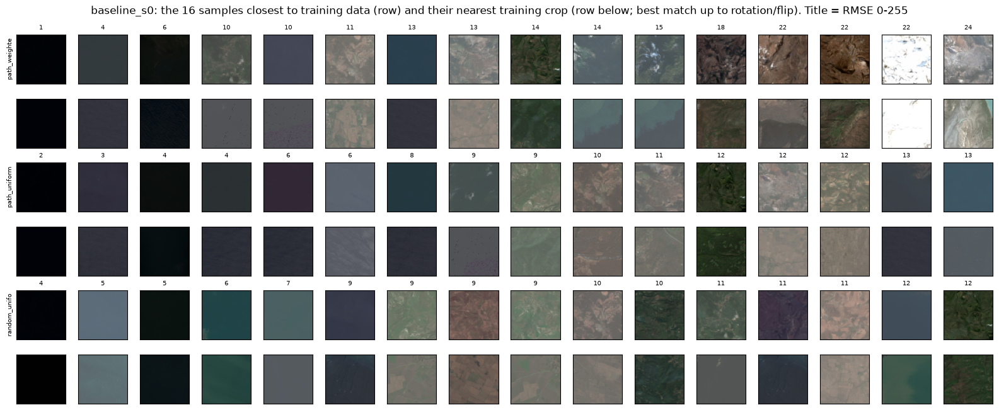

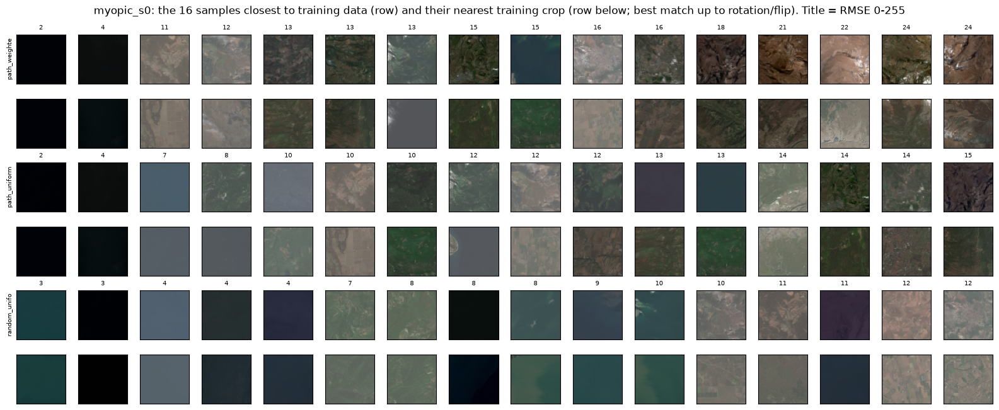

In [5]:
def crop_at(a):
    t, y, x = a; return np.asarray(tiles_all[t, y:y + 64, x:x + 64])
for a in agents:
    fig, axes = plt.subplots(6, 16, figsize=(16, 6.6))
    for j, s in enumerate(SETS):
        m = mem[(a, s)]; order = np.argsort(m['sample_rmse'])[:16]   # the 16 closest = worst case
        for k, i in enumerate(order):
            axes[2 * j, k].imshow(samples[a][s][i]); axes[2 * j, k].set_title(f'{m["sample_rmse"][i]:.0f}', fontsize=7)
            axes[2 * j + 1, k].imshow(crop_at(m['arg'][i]))
        axes[2 * j, 0].set_ylabel(s[:12], fontsize=7)
    for ax in axes.flat: ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f'{a}: the 16 samples closest to training data (row) and their nearest training crop (row below; best match up to rotation/flip). Title = RMSE 0-255')
    fig.tight_layout(); plt.show()

## 3. Cheap statistics
Colour histogram: joint RGB, 8 bins per channel; distance = Jensen–Shannon (base 2, 0 = identical, 1 = disjoint).
Brightness = mean of RGB/255; saturation = HSV S. Diversity = mean pairwise pixel RMSE between the 64 images.

In [6]:
def hist(imgs):
    q = (imgs.reshape(-1, 3) // 32).astype(np.int64)
    h = np.bincount(q[:, 0] * 64 + q[:, 1] * 8 + q[:, 2], minlength=512).astype(float)
    return h / h.sum()
def js(p, q):
    m = (p + q) / 2
    kl = lambda a, b: np.sum(np.where(a > 0, a * np.log2(np.where(a > 0, a, 1) / np.where(b > 0, b, 1)), 0))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)
def summ(imgs):
    f = imgs.astype(np.float32) / 255
    hsv = rgb_to_hsv(f.reshape(-1, 3))
    x = torch.from_numpy(f.reshape(len(f), -1)).to(dev)
    pd_ = torch.cdist(x, x) / np.sqrt(x.shape[1]) * 255
    return {'brightness': f.mean(), 'saturation': hsv[:, 1].mean(), 'r': f[..., 0].mean(), 'g': f[..., 1].mean(), 'b': f[..., 2].mean(),
            'diversity_rmse': float(pd_.sum() / (len(f) * (len(f) - 1)))}

rows = []
for a in agents:
    for s in SETS:
        rows.append({'agent': a, 'set': s, 'kind': 'samples', **summ(samples[a][s])})
        rows.append({'agent': a, 'set': s, 'kind': 'real', **summ(reals[a][s])})
stat = pd.DataFrame(rows).set_index(['agent', 'kind', 'set']).sort_index()
stat

brightness  saturation       r       g       b  diversity_rmse
agent       kind    set                                                                           
baseline_s0 real    path_uniform        0.4430      0.2040  0.4477  0.4508  0.4306         88.9423
                    path_weighted       0.5375      0.1864  0.5445  0.5440  0.5241        112.1546
                    random_uniform      0.4140      0.1681  0.4185  0.4277  0.3958         64.8629
            samples path_uniform        0.5110      0.2133  0.5204  0.5162  0.4965         92.5269
                    path_weighted       0.5654      0.1838  0.5607  0.5707  0.5649        100.6744
                    random_uniform      0.5291      0.2477  0.5346  0.5365  0.5162         84.6275
myopic_s0   real    path_uniform        0.5217      0.1568  0.5256  0.5301  0.5094        101.0675
                    path_weighted       0.4769      0.1958  0.4794  0.4825  0.4688        110.8834
                    random_uniform      0.3943      0.1797  0.4005  0.4071  0.3752         66.9988
            samples path_uniform        0.5390      0.1853  0.5495  0.5439  0.5237         93.7085
                    path_weighted       0.5319      0.1971  0.5350  0.5367  0.5242        102.5044
                    random_uniform      0.4928      0.2595  0.4984  0.4992  0.4807         83.8231

Noise floor: spread of each statistic and of JS distance across 20 independent batches of 64 real crops from one set (`random_uniform`).

In [7]:
floor = {}
for a in agents:
    bs = [real_crops(a, 'random_uniform', 64, 100 + i) for i in range(20)]
    sm = pd.DataFrame([summ(b) for b in bs])
    hs = [hist(b) for b in bs]
    jsd = [js(hs[i], hs[j]) for i in range(20) for j in range(i + 1, 20)]
    floor[a] = {**{f'{c}_sd': sm[c].std() for c in sm}, 'js_median': np.median(jsd), 'js_p95': np.percentile(jsd, 95)}
pd.DataFrame(floor).T

,brightness_sd,saturation_sd,r_sd,g_sd,b_sd,diversity_rmse_sd,js_median,js_p95
baseline_s0,0.0213,0.0170,0.0209,0.0203,0.0228,7.8118,0.0378,0.060
myopic_s0,0.0283,0.0215,0.0287,0.0283,0.0283,8.8332,0.0413,0.072


In [8]:
pairs = [('path_weighted', 'random_uniform'), ('path_uniform', 'random_uniform'), ('path_weighted', 'path_uniform')]
rows = []
for a in agents:
    for kind, src in [('samples', samples), ('real', reals)]:
        for p, q in pairs:
            sp, sq = summ(src[a][p]), summ(src[a][q])
            rows.append({'agent': a, 'kind': kind, 'pair': f'{p} vs {q}', 'js_hist': js(hist(src[a][p]), hist(src[a][q])),
                         **{f'd_{c}': sp[c] - sq[c] for c in ['brightness', 'saturation', 'diversity_rmse']}})
cmp = pd.DataFrame(rows).set_index(['agent', 'kind', 'pair'])
cmp['js_over_floor_p95'] = [r.js_hist / floor[a]['js_p95'] for (a, _, _), r in cmp.iterrows()]
for c in ['brightness', 'saturation', 'diversity_rmse']:
    cmp[f'd_{c}_in_sd'] = [r[f'd_{c}'] / floor[a][f'{c}_sd'] for (a, _, _), r in cmp.iterrows()]
cmp

js_hist  d_brightness  d_saturation  d_diversity_rmse  js_over_floor_p95  d_brightness_in_sd  d_saturation_in_sd  d_diversity_rmse_in_sd
agent       kind    pair                                                                                                                                                                     
baseline_s0 samples path_weighted vs random_uniform   0.0900        0.0363       -0.0639           16.0469             1.5019              1.7079             -3.7528                  2.0542
                    path_uniform vs random_uniform    0.0822       -0.0181       -0.0345            7.8994             1.3712             -0.8513             -2.0226                  1.0112
                    path_weighted vs path_uniform     0.0405        0.0544       -0.0295            8.1475             0.6759              2.5592             -1.7302                  1.0430
            real    path_weighted vs random_uniform   0.1536        0.1235        0.0183           47.2917             2.5626              5.8127              1.0765                  6.0539
                    path_uniform vs random_uniform    0.0559        0.0290        0.0359           24.0794             0.9316              1.3647              2.1105                  3.0824
                    path_weighted vs path_uniform     0.0689        0.0945       -0.0176           23.2123             1.1492              4.4480             -1.0340                  2.9714
myopic_s0   samples path_weighted vs random_uniform   0.0992        0.0392       -0.0625           18.6813             1.3784              1.3852             -2.9059                  2.1149
                    path_uniform vs random_uniform    0.1107        0.0463       -0.0742            9.8853             1.5385              1.6361             -3.4537                  1.1191
                    path_weighted vs path_uniform     0.0284       -0.0071        0.0118            8.7959             0.3941             -0.2509              0.5478                  0.9958
            real    path_weighted vs random_uniform   0.1423        0.0826        0.0161           43.8846             1.9767              2.9225              0.7485                  4.9681
                    path_uniform vs random_uniform    0.0959        0.1275       -0.0229           34.0687             1.3328              4.5075             -1.0672                  3.8569
                    path_weighted vs path_uniform     0.0785       -0.0448        0.0390            9.8159             1.0905             -1.5850              1.8157                  1.1112

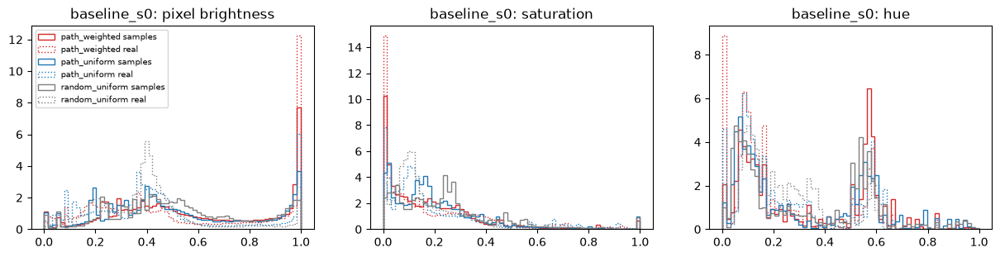

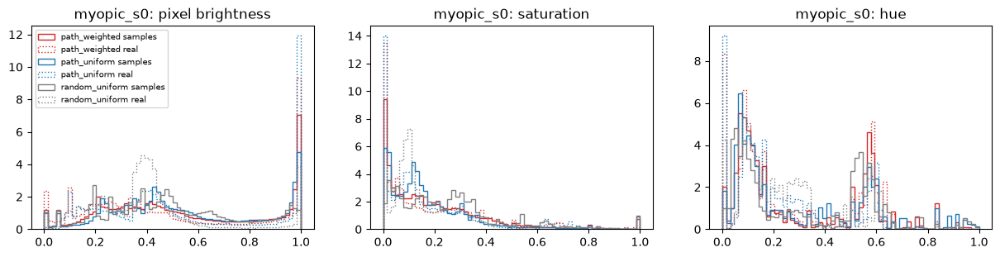

In [9]:
for a in agents:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
    for s, c in zip(SETS, ['C3', 'C0', 'C7']):
        for kind, src, ls in [('samples', samples, '-'), ('real', reals, ':')]:
            f = src[a][s].astype(np.float32) / 255
            hsv = rgb_to_hsv(f.reshape(-1, 3))
            axes[0].hist(f.mean(-1).ravel(), 64, range=(0, 1), histtype='step', color=c, ls=ls, density=True, label=f'{s} {kind}')
            axes[1].hist(hsv[:, 1], 64, range=(0, 1), histtype='step', color=c, ls=ls, density=True)
            axes[2].hist(hsv[:, 0], 64, range=(0, 1), histtype='step', color=c, ls=ls, density=True)
    for ax, t in zip(axes, ['pixel brightness', 'saturation', 'hue']): ax.set_title(f'{a}: {t}')
    axes[0].legend(fontsize=7); plt.show()

## 3b. Same noise, same dream? And do samples follow their data's composition?
Same-index RMSE between models (identical noise) vs RMSE between different samples. Then the share of bright (mean > 0.6, mostly snow)
and dark (mean < 0.12, deep water) images in samples vs 2,000 real crops of the same training set.

In [10]:
rows = []
for a in agents:
    S = {s: samples[a][s].astype(np.float32) / 255 for s in SETS}
    rm = lambda x, y: np.sqrt(((x - y) ** 2).mean((1, 2, 3))) * 255
    for i, p in enumerate(SETS):
        for q in SETS[i + 1:]:
            rows.append({'agent': a, 'pair': f'{p} vs {q}', 'same_noise_rmse': rm(S[p], S[q]).mean(),
                         'different_sample_rmse': np.mean([rm(S[p], np.roll(S[q], k, 0)).mean() for k in range(1, 64)])})
display(pd.DataFrame(rows).set_index(['agent', 'pair']))
rows = []
for a in agents:
    for s in SETS:
        r = real_crops(a, s, 2000, 5).astype(np.float32) / 255; m_r = r.mean((1, 2, 3))
        x = samples[a][s].astype(np.float32) / 255; m_s = x.mean((1, 2, 3))
        rows.append({'agent': a, 'set': s, 'real_bright': (m_r > 0.6).mean(), 'samples_bright': (m_s > 0.6).mean(),
                     'real_dark': (m_r < 0.12).mean(), 'samples_dark': (m_s < 0.12).mean(), 'real_brightness': m_r.mean(), 'samples_brightness': m_s.mean()})
pd.DataFrame(rows).set_index(['agent', 'set'])

same_noise_rmse  different_sample_rmse
agent       pair                                                                   
baseline_s0 path_weighted vs path_uniform            24.6166                97.6727
            path_weighted vs random_uniform          28.7672                93.5368
            path_uniform vs random_uniform           15.5555                88.8459
myopic_s0   path_weighted vs path_uniform            15.6637                98.2993
            path_weighted vs random_uniform          31.9297                94.2025
            path_uniform vs random_uniform           23.6777                89.4628

real_bright  samples_bright  real_dark  samples_dark  real_brightness  samples_brightness
agent       set                                                                                                      
baseline_s0 path_weighted        0.3960          0.4688     0.0365        0.0312           0.5193              0.5654
            path_uniform         0.2600          0.3750     0.0825        0.0469           0.4464              0.5110
            random_uniform       0.1040          0.3750     0.0560        0.0312           0.3886              0.5291
myopic_s0   path_weighted        0.4505          0.3906     0.0275        0.0312           0.5601              0.5319
            path_uniform         0.3720          0.4062     0.0685        0.0469           0.5184              0.5390
            random_uniform       0.1075          0.3594     0.0370        0.0469           0.3794              0.4928

## 4. Observations (descriptive, one line per model)
*(written after running; see `notes/observations.md`)*